### Import Data

In [3]:
import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

import os
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

from sklearn.feature_selection import VarianceThreshold

print(os.getcwd())
df = pd.read_csv("../dataset/fab.csv")

d:\CODE\MyNote\SemiconductorData\code


### Data Information

In [4]:
df.info()

# dtypes: float64(590) -> Sensor, int64(1) -> Pass_Fail, str(1) -> SensorTime
df.dtypes 

df.describe()

df.head()
df.tail()

<class 'pandas.DataFrame'>
RangeIndex: 1567 entries, 0 to 1566
Columns: 592 entries, SensorTime to Pass_Fail
dtypes: float64(590), int64(1), str(1)
memory usage: 7.1 MB


,SensorTime,Sensor0,Sensor1,Sensor2,Sensor3,Sensor4,Sensor5,Sensor6,Sensor7,Sensor8,...,Sensor581,Sensor582,Sensor583,Sensor584,Sensor585,Sensor586,Sensor587,Sensor588,Sensor589,Pass_Fail
1562,2008-10-16 15:13:00,2899.41,2464.36,2179.7333,3085.3781,1.4843,100.0,82.2467,0.1248,1.3424,...,203.1720,0.4988,0.0143,0.0039,2.8669,0.0068,0.0138,0.0047,203.1720,-1
1563,2008-10-16 20:49:00,3052.31,2522.55,2198.5667,1124.6595,0.8763,100.0,98.4689,0.1205,1.4333,...,NaN,0.4975,0.0131,0.0036,2.6238,0.0068,0.0138,0.0047,203.1720,-1
1564,2008-10-17 05:26:00,2978.81,2379.78,2206.3000,1110.4967,0.8236,100.0,99.4122,0.1208,NaN,...,43.5231,0.4987,0.0153,0.0041,3.0590,0.0197,0.0086,0.0025,43.5231,-1
1565,2008-10-17 06:01:00,2894.92,2532.01,2177.0333,1183.7287,1.5726,100.0,98.7978,0.1213,1.4622,...,93.4941,0.5004,0.0178,0.0038,3.5662,0.0262,0.0245,0.0075,93.4941,-1
1566,2008-10-17 06:07:00,2944.92,2450.76,2195.4444,2914.1792,1.5978,100.0,85.1011,0.1235,NaN,...,137.7844,0.4987,0.0181,0.0040,3.6275,0.0117,0.0162,0.0045,137.7844,-1


### Set Target / Feature

In [5]:
target_col = "Pass_Fail"

feature_cols = [
    col for col in df.columns 
    if col not in ['Pass_Fail', 'SensorTime']
]

### Data Visualization

- 정상/불량 비율 확인

Pass_Fail
-1    1463
 1     104
Name: count, dtype: int64


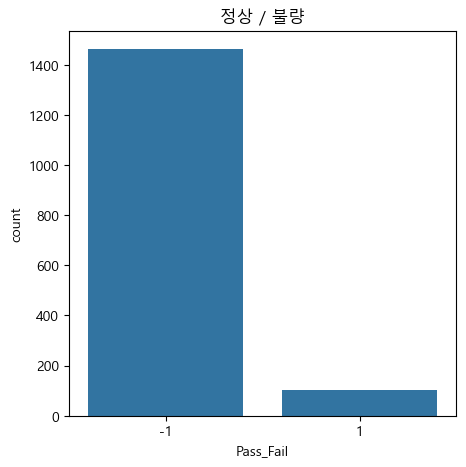

In [6]:
print(df['Pass_Fail'].value_counts())

plt.rcParams['font.family'] ='Malgun Gothic'
plt.rcParams['axes.unicode_minus'] =False

plt.figure(figsize=(5,5))
sns.countplot(x='Pass_Fail', data=df)
plt.title('정상 / 불량')
plt.show()

- 센서별 Pass / Fail 데이터 분포

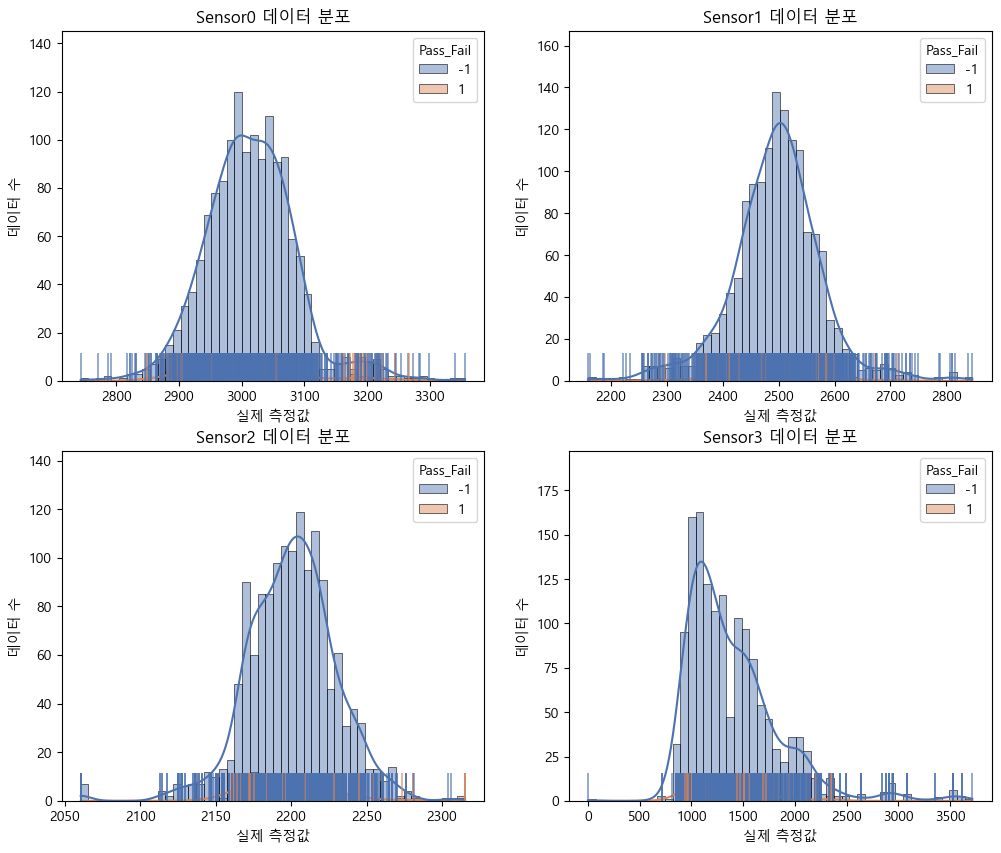

In [7]:
palette = {
    -1: "#4C72B0",   # Pass
     1: "#DD8452"    # Fail
}

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.ravel()

for i, sensor in enumerate(feature_cols[0:4]):
    sns.histplot(data=df,
                x=sensor,
                hue="Pass_Fail",
                bins=50,
                kde=True,
                palette=palette,
                alpha=0.45,
                edgecolor="black",
                linewidth=0.4,
                multiple="layer",
                ax=axes[i])
    sns.rugplot(data=df,
                x=sensor,
                hue="Pass_Fail",
                palette=palette,
                height=0.08,
                alpha=0.7,
                linewidth=1.2,
                ax=axes[i],
                legend=False)

    axes[i].set_title(f"{sensor} 데이터 분포")
    axes[i].set_xlabel("실제 측정값")
    axes[i].set_ylabel("데이터 수")

### Data Preprocessing

- 결측치 처리 

In [8]:
# 결측값이 높은 feature 제거
missing_ratio = df[feature_cols].isnull().mean().sort_values(ascending=False) * 100
missing_ratio
high_missing_features = missing_ratio[missing_ratio > 70 ].index.tolist()
df = df.drop(columns=high_missing_features)

feature_cols = [
    col for col in df.columns 
    if col not in ['Pass_Fail', 'SensorTime']
]

# 나머지 결측치 데이터 중앙값으로 처리
df[feature_cols] = df[feature_cols].fillna(df[feature_cols].median())
print(df.isna().sum().sum())
print(df[feature_cols].isna().mean().sort_values(ascending=False).head())

0
Sensor0    0.0
Sensor1    0.0
Sensor2    0.0
Sensor3    0.0
Sensor4    0.0
dtype: float64


- 중복 데이터 처리

In [9]:
duplicate_count = df.duplicated(subset=feature_cols + [target_col]).sum()
duplicate_count
# 중복 데이터 확인 결과, 전체 행 기준 중복 데이터는 존재하지 않았다.

np.int64(0)

- 이상치 처리

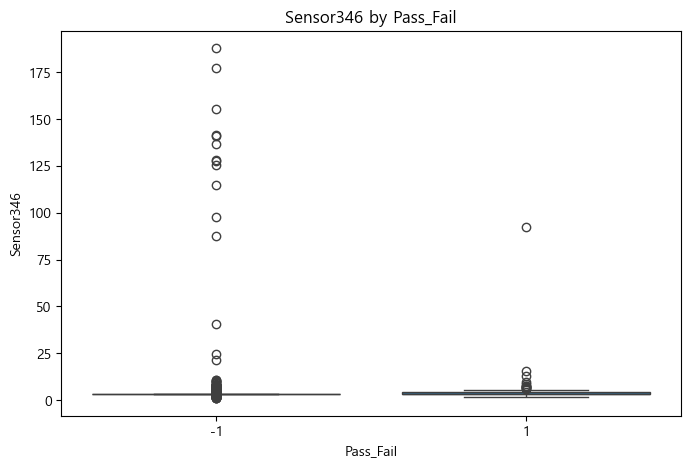

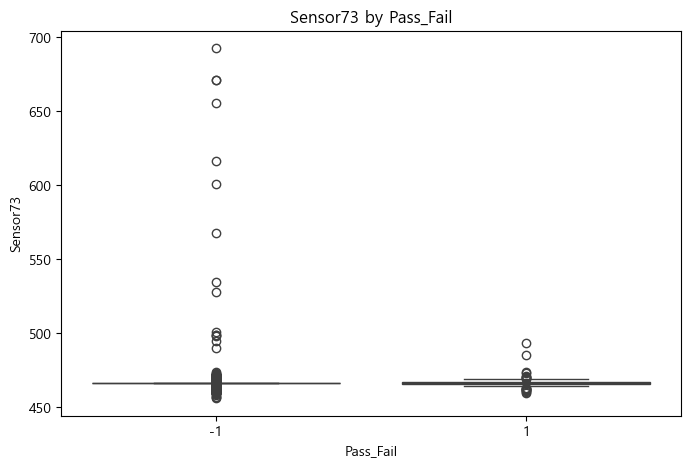

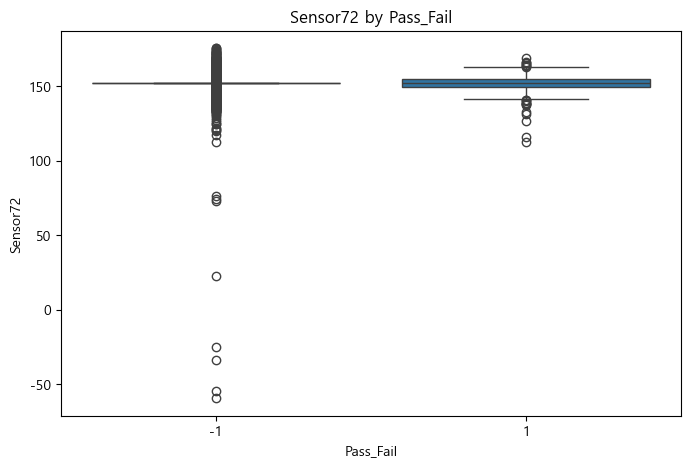

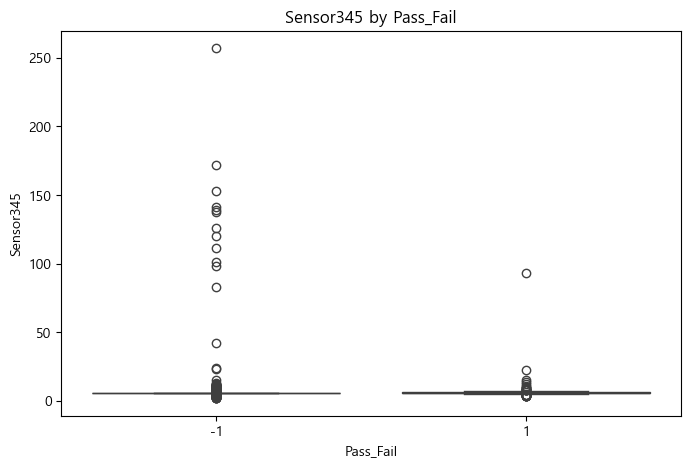

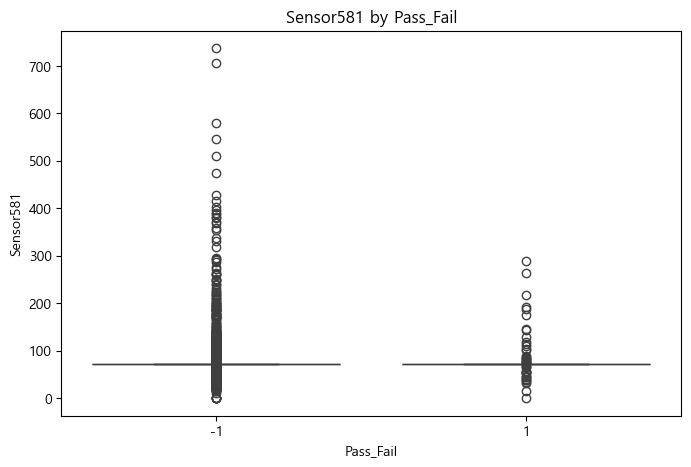

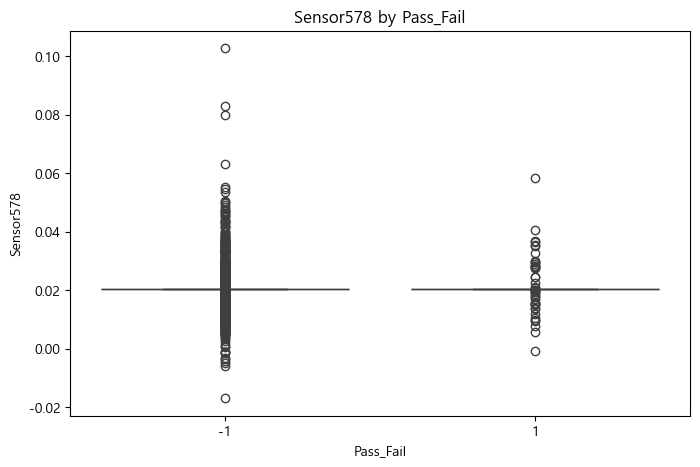

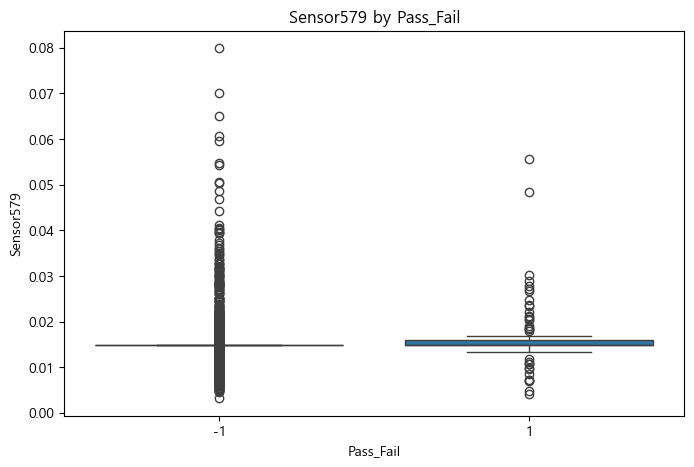

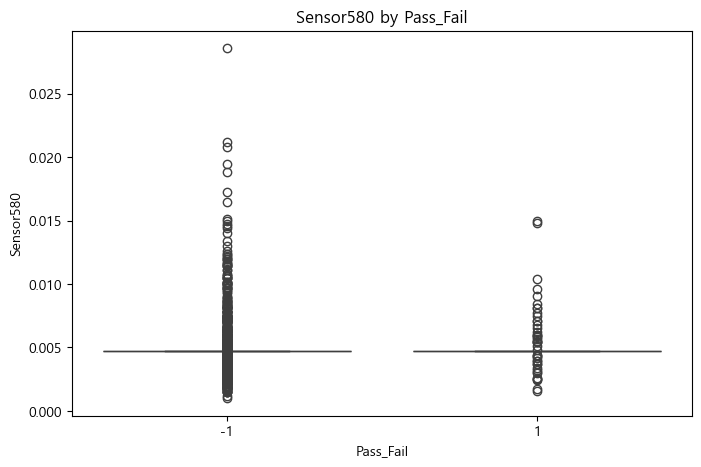

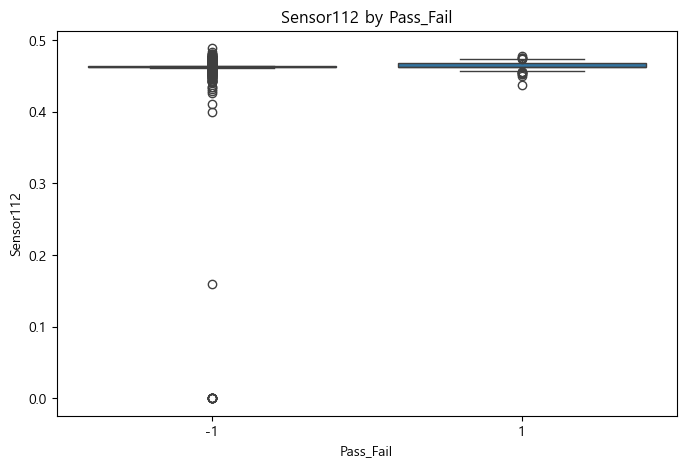

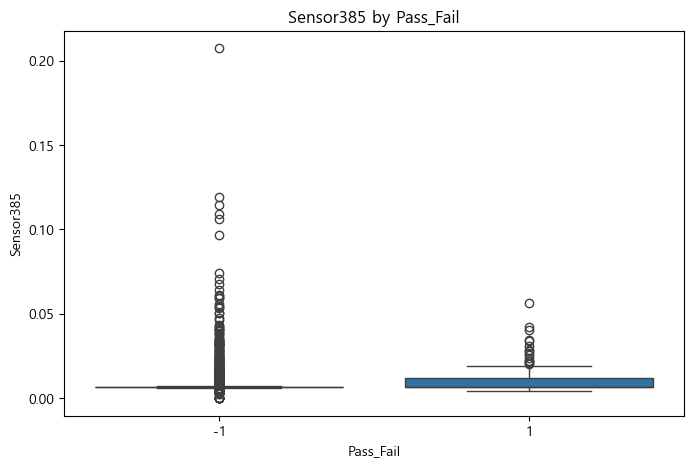

In [10]:
outliers_result = {}
for col in feature_cols:
    Q1 = np.nanquantile(df[col], 0.25)
    Q3 = np.nanquantile(df[col], 0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    
    outliers_result[col] = len(outliers)
outliers_result = pd.Series(outliers_result).sort_values(ascending=False)
top_features = outliers_result.head(10).index
for col in top_features:
    plt.figure(figsize=(8, 5))
    sns.boxplot(data=df, x='Pass_Fail', y=col)
    plt.title(f'{col} by Pass_Fail')
    plt.show()

### Zero Variance

In [11]:
thresholder = VarianceThreshold(threshold=0)
_ = thresholder.fit_transform(df[feature_cols])

mask = ~thresholder.get_support()
cols_zero_var_drop = np.asarray(feature_cols)[mask].tolist()
print(f'** {len(cols_zero_var_drop)} Features to Drop by Low Variance')
print(f'{cols_zero_var_drop}')

df = df.drop(columns=cols_zero_var_drop)
feature_cols = [
    col for col in df.columns 
    if col not in ['Pass_Fail', 'SensorTime']
]

** 116 Features to Drop by Low Variance
['Sensor5', 'Sensor13', 'Sensor42', 'Sensor49', 'Sensor52', 'Sensor69', 'Sensor97', 'Sensor141', 'Sensor149', 'Sensor178', 'Sensor179', 'Sensor186', 'Sensor189', 'Sensor190', 'Sensor191', 'Sensor192', 'Sensor193', 'Sensor194', 'Sensor226', 'Sensor229', 'Sensor230', 'Sensor231', 'Sensor232', 'Sensor233', 'Sensor234', 'Sensor235', 'Sensor236', 'Sensor237', 'Sensor240', 'Sensor241', 'Sensor242', 'Sensor243', 'Sensor256', 'Sensor257', 'Sensor258', 'Sensor259', 'Sensor260', 'Sensor261', 'Sensor262', 'Sensor263', 'Sensor264', 'Sensor265', 'Sensor266', 'Sensor276', 'Sensor284', 'Sensor313', 'Sensor314', 'Sensor315', 'Sensor322', 'Sensor325', 'Sensor326', 'Sensor327', 'Sensor328', 'Sensor329', 'Sensor330', 'Sensor364', 'Sensor369', 'Sensor370', 'Sensor371', 'Sensor372', 'Sensor373', 'Sensor374', 'Sensor375', 'Sensor378', 'Sensor379', 'Sensor380', 'Sensor381', 'Sensor394', 'Sensor395', 'Sensor396', 'Sensor397', 'Sensor398', 'Sensor399', 'Sensor400', 'Sens

### Remove Collinear Features

In [12]:
corr_matrix = df[feature_cols].corr(method="pearson").abs()

threshold = 0.95
drop_cols = set()

for i in range(len(corr_matrix.columns) - 1):
    for j in range(i + 1):
        col = corr_matrix.columns[i + 1]
        row = corr_matrix.index[j]
        val = corr_matrix.iloc[j, i + 1]

        if val >= threshold:
            print(col, "|", row, "|", round(val, 2))
            drop_cols.add(col)
drop_cols = list(drop_cols)
print(len(drop_cols),"개")

df = df.drop(columns=drop_cols)
feature_cols = [
    col for col in df.columns 
    if col not in ['Pass_Fail', 'SensorTime']
]

Sensor27 | Sensor25 | 0.98
Sensor36 | Sensor34 | 1.0
Sensor96 | Sensor94 | 0.96
Sensor104 | Sensor99 | 0.99
Sensor105 | Sensor92 | 0.99
Sensor106 | Sensor93 | 0.99
Sensor127 | Sensor122 | 0.96
Sensor140 | Sensor4 | 1.0
Sensor148 | Sensor16 | 0.97
Sensor152 | Sensor16 | 0.98
Sensor152 | Sensor148 | 0.99
Sensor165 | Sensor164 | 0.96
Sensor174 | Sensor172 | 1.0
Sensor206 | Sensor74 | 1.0
Sensor209 | Sensor74 | 1.0
Sensor209 | Sensor206 | 1.0
Sensor244 | Sensor109 | 0.96
Sensor245 | Sensor244 | 0.97
Sensor246 | Sensor244 | 0.99
Sensor246 | Sensor245 | 0.97
Sensor249 | Sensor114 | 0.98
Sensor252 | Sensor117 | 0.99
Sensor271 | Sensor136 | 0.97
Sensor272 | Sensor137 | 0.98
Sensor274 | Sensor139 | 0.99
Sensor275 | Sensor4 | 1.0
Sensor275 | Sensor140 | 1.0
Sensor277 | Sensor142 | 0.97
Sensor279 | Sensor144 | 0.98
Sensor280 | Sensor145 | 0.96
Sensor281 | Sensor146 | 0.95
Sensor282 | Sensor147 | 1.0
Sensor283 | Sensor16 | 0.97
Sensor283 | Sensor148 | 1.0
Sensor283 | Sensor152 | 0.99
Sensor285 | S

### Split Train / Test

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    df[feature_cols], df[target_col], random_state=0, stratify=df[target_col]
) 

print(X_train.shape)
print(X_test.shape)

print(y_train.shape)
print(y_test.shape)

(1175, 281)
(392, 281)
(1175,)
(392,)


### Check Variable

In [14]:
cat_cols = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

print("문자형 컬럼 개수:", len(cat_cols))
print(cat_cols)

문자형 컬럼 개수: 0
[]


### StandardScaler